## 1. Công cụ


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score, precision_score, recall_score
pd.options.display.float_format = '{:,.2f}'.format


## 2. Chia Train/Test



In [2]:
url = 'https://raw.githubusercontent.com/huy1907ddddddd/DS66B_group_14/eaabc962460c76dc76db4a59d3de5a5dfd6329fd/data/raw/Tetuan%20City%20power%20consumption.csv'
data = pd.read_csv(url)
train_end = int(len(data) * 0.70)
test_start = int(len(data) * (0.70 + 0.15))
test = data.iloc[test_start:].copy()  # Giữ riêng; chỉ dùng ở phần chấm cuối.
df = data.iloc[:test_start].copy()  # Chỉ train và validation.
del data
weather = ['temperature', 'humidity', 'wind_speed', 'general_diffuse', 'diffuse']
zones = ['zone_1', 'zone_2', 'zone_3']
df.columns = ['time'] + weather + zones
df['time'] = pd.to_datetime(df['time'], format='%m/%d/%Y %H:%M')
display(df.head(2))


,time,temperature,humidity,wind_speed,general_diffuse,diffuse,zone_1,zone_2,zone_3
0,2017-01-01 00:00:00,6.56,73.80,0.08,0.05,0.12,"34,055.70","16,128.88","20,240.96"
1,2017-01-01 00:10:00,6.41,74.50,0.08,0.07,0.09,"29,814.68","19,375.08","20,131.08"


### EDA — Kiểm tra dữ liệu
Kiểm tra ô trống, giờ trùng và khoảng cách 10 phút


In [3]:
display(pd.Series({'rows': len(df), 'missing cells': df.isna().sum().sum(),
                   'duplicate times': df.time.duplicated().sum()}))
assert df.notna().all().all()
assert not df.time.duplicated().any()
assert df.time.diff().dropna().eq(pd.Timedelta(minutes=10)).all()
assert np.isfinite(df[weather + zones]).all().all()


rows               44553
missing cells          0
duplicate times        0
dtype: int64

### EDA — Xem dữ liệu train


,count,mean,std,min,25%,50%,75%,max
temperature,"36,691.00",19.24,6.18,3.25,14.34,19.16,24.04,40.01
humidity,"36,691.00",67.66,16.08,11.34,57.38,69.52,81.40,93.60
wind_speed,"36,691.00",2.00,2.36,0.05,0.08,0.09,4.91,4.98
general_diffuse,"36,691.00",207.66,285.73,0.00,0.07,18.21,383.20,"1,163.00"
diffuse,"36,691.00",86.54,135.88,0.02,0.13,16.44,119.80,936.00
zone_1,"36,691.00","32,956.89","7,255.59","13,895.70","26,703.42","33,089.36","38,195.88","52,204.40"
zone_2,"36,691.00","20,444.84","5,067.72","8,560.08","16,298.76","20,444.35","23,875.62","37,408.86"
zone_3,"36,691.00","20,024.41","6,464.38","8,189.91","15,290.18","18,071.63","24,821.57","47,598.33"


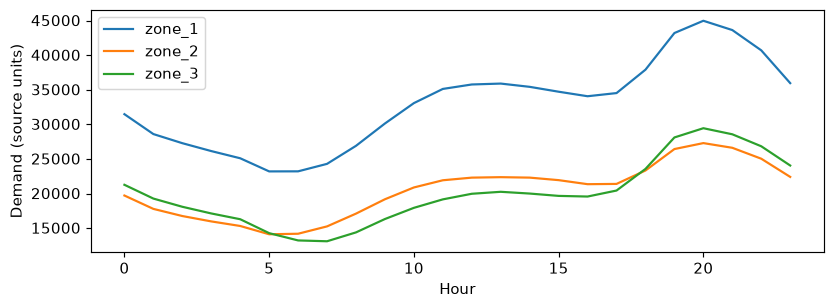

In [4]:
early = df.iloc[:train_end]
display(early[weather + zones].describe().T)
early.groupby(early.time.dt.hour)[zones].mean().plot(figsize=(9, 3), ylabel='Demand (source units)', xlabel='Hour')
plt.show()


## 3. Feature Engineering — Tạo đầu vào
Mỗi dòng có 48 thông tin:
- 8 số đo hiện tại.
- 18 số đo quá khứ.
- 12 số trung bình và mức dao động gần đây.
- 3 số điện cùng khung giờ hôm trước.
- 7 thông tin về giờ, thứ và mùa.

Giờ dùng sin/cos để nối cuối ngày với đầu ngày.
Hàm make_features tạo đầu vào theo cùng một cách cho các tập dữ liệu.


In [5]:
horizon = 3  # 3 dòng × 10 phút = 30 phút.

def make_features(frame):
    future_time = frame.time + pd.Timedelta(minutes=30)
    X = frame[weather + zones].copy()
    for zone in zones:
        for lag in [1, 3, 6, 18, 144, 1008]:
            X[f'{zone}_lag_{lag}'] = frame[zone].shift(lag)
        for window in [6, 18]:
            X[f'{zone}_mean_{window}'] = frame[zone].rolling(window).mean()
            X[f'{zone}_std_{window}'] = frame[zone].rolling(window).std()
        X[f'{zone}_daily_reference'] = frame[zone].shift(144 - horizon)
    minute = future_time.dt.hour * 60 + future_time.dt.minute
    X['clock_sin'] = np.sin(2 * np.pi * minute / 1440)
    X['clock_cos'] = np.cos(2 * np.pi * minute / 1440)
    X['weekday_sin'] = np.sin(2 * np.pi * future_time.dt.dayofweek / 7)
    X['weekday_cos'] = np.cos(2 * np.pi * future_time.dt.dayofweek / 7)
    X['year_sin'] = np.sin(2 * np.pi * future_time.dt.dayofyear / 365.25)
    X['year_cos'] = np.cos(2 * np.pi * future_time.dt.dayofyear / 365.25)
    X['is_weekend'] = (future_time.dt.dayofweek >= 5).astype(float)
    y = frame[zones].shift(-horizon)
    valid = X.notna().all(axis=1) & y.notna().all(axis=1)
    X, y = X.loc[valid], y.loc[valid]
    origin, target_time = frame.time.loc[valid], future_time.loc[valid]
    return X, y, origin, target_time

X, y, origin, target_time = make_features(df)
print('Inputs per row:', X.shape[1])
display(X.head(2))


Inputs per row: 48


,temperature,humidity,wind_speed,general_diffuse,diffuse,zone_1,zone_2,zone_3,zone_1_lag_1,zone_1_lag_3,zone_1_lag_6,zone_1_lag_18,zone_1_lag_144,zone_1_lag_1008,zone_1_mean_6,zone_1_std_6,zone_1_mean_18,zone_1_std_18,zone_1_daily_reference,zone_2_lag_1,zone_2_lag_3,zone_2_lag_6,zone_2_lag_18,zone_2_lag_144,zone_2_lag_1008,zone_2_mean_6,zone_2_std_6,zone_2_mean_18,zone_2_std_18,zone_2_daily_reference,zone_3_lag_1,zone_3_lag_3,zone_3_lag_6,zone_3_lag_18,zone_3_lag_144,zone_3_lag_1008,zone_3_mean_6,zone_3_std_6,zone_3_mean_18,zone_3_std_18,zone_3_daily_reference,clock_sin,clock_cos,weekday_sin,weekday_cos,year_sin,year_cos,is_weekend
1008,14.07,78.20,0.08,0.05,0.13,"28,332.15","18,386.63","19,032.29","29,401.52","30,914.43","33,812.66","40,265.32","28,927.59","34,055.70","30,612.66","1,672.95","34,929.96","3,663.00","26,831.39","19,145.29","19,809.12","21,125.84","24,970.21","18,875.38","16,128.88","19,674.77",866.59,"22,139.21","2,106.99","17,445.59","19,870.84","20,686.27","22,074.22","25,601.93","18,529.16","20,240.96","20,492.53",983.48,"22,805.78","1,968.41","17,123.86",0.13,0.99,-0.78,0.62,0.14,0.99,1.00
1009,14.19,77.80,0.09,0.04,0.11,"27,791.39","17,934.35","18,639.04","28,332.15","30,203.54","32,955.95","40,034.43","28,052.66","29,814.68","29,751.90","1,550.28","34,249.79","3,793.76","26,363.54","18,386.63","19,546.50","20,844.98","24,838.91","18,477.81","19,375.08","19,189.67",894.72,"21,755.62","2,212.45","17,186.63","19,032.29","20,298.80","21,727.23","25,457.35","18,153.25","20,131.08","19,977.83","1,015.64","22,426.99","2,080.97","16,684.34",0.17,0.98,-0.78,0.62,0.14,0.99,1.00


### Chia train và validation
Trong phần dữ liệu còn lại: lấy mốc 70% ban đầu làm ranh giới.
Train dùng để học; validation dùng để so sánh và chọn cách làm.
Loại dòng có đáp án sau 30 phút vượt ranh giới. Không xáo trộn.


In [6]:
validation_start = df.time.iloc[train_end]
train = target_time < validation_start
validation = origin >= validation_start
X_train, y_train = X.loc[train], y.loc[train]
X_val, y_val = X.loc[validation], y.loc[validation]
display(pd.DataFrame({'rows': [train.sum(), validation.sum()],
                      'first forecast time': [origin[train].min(), origin[validation].min()],
                      'last answer time': [target_time[train].max(), target_time[validation].max()]},
                     index=['Train', 'Validation']))
assert target_time[train].max() < origin[validation].min()


,rows,first forecast time,last answer time
Train,35680,2017-01-08 00:00:00,2017-09-12 19:00:00
Validation,7859,2017-09-12 19:10:00,2017-11-06 09:20:00


## 4. Model — Chạy và so sánh mô hình
Chạy Linear, Ridge, Lasso, KNN, cây và rừng trên cùng dữ liệu.
So thêm 2 cách đoán: giống hiện tại; giống cùng giờ hôm qua.
MAE = trung bình lệch bao nhiêu. Càng nhỏ càng tốt. Giữ đơn vị gốc của dữ liệu.


In [7]:
predictions = {'Persistence': X_val[zones].to_numpy(),
               'Previous day': X_val[[f'{z}_daily_reference' for z in zones]].to_numpy()}
models = {
    'Linear': make_pipeline(StandardScaler(), LinearRegression()),
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=100)),
    'Lasso': make_pipeline(StandardScaler(), Lasso(alpha=10, max_iter=3000, tol=0.001)),
    'KNN': make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=15, weights='distance', n_jobs=2)),
    'Decision Tree': DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=60, max_depth=14,
                                         min_samples_leaf=5, max_features=0.8,
                                         random_state=42, n_jobs=2)
}


Chuẩn hóa giúp các cột có thang đo tương đương; chỉ học cách chuẩn hóa từ train.
fit: cho học. predict: cho dự đoán. Vòng lặp làm giống nhau cho 6 mô hình.


,zone_1,zone_2,zone_3,MAE
Model,,,,
Linear,407.83,283.39,265.74,318.99
Lasso,428.96,307.52,279.70,338.73
Ridge,456.18,299.08,299.09,351.45
Persistence,"1,099.94",733.55,540.47,791.32
Previous day,"1,158.57","1,320.24",594.55,"1,024.45"
Random Forest,981.78,"1,440.54","1,246.74","1,223.02"
Decision Tree,"1,301.26","1,775.32","1,552.87","1,543.15"
KNN,"1,572.26","1,377.21","2,146.93","1,698.80"


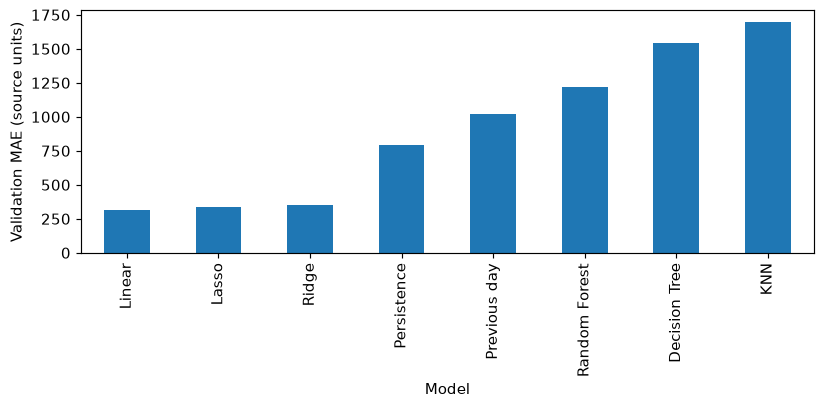

In [8]:
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_val)
scores = []
for name, prediction in predictions.items():
    errors = mean_absolute_error(y_val, prediction, multioutput='raw_values')
    scores.append([name, *errors, errors.mean()])
results = pd.DataFrame(scores, columns=['Model', *zones, 'MAE']).set_index('Model').sort_values('MAE')
display(results)
results.MAE.plot.bar(figsize=(9, 3), ylabel='Validation MAE (source units)')
plt.show()


## 5. Xem một dự đoán thật
Lấy một thời điểm. So số đoán với số thật; lấy độ lệch không âm.
Sai số của một thời điểm khác MAE của cả tập.
Đây là số điện tại thời điểm sau 30 phút, không phải tổng điện trong 30 phút.


In [9]:
sample = X_val.iloc[[0]]
prediction = models['Linear'].predict(sample)[0]
example = pd.DataFrame({'Current': sample[zones].iloc[0], 'Actual in 30 min': y_val.iloc[0], 'Linear': prediction})
example['Absolute error'] = (example['Actual in 30 min'] - example.Linear).abs()
print('Forecast made at:', origin[validation].iloc[0], ' | Answer at:', target_time[validation].iloc[0])
display(example)
print('MAE at this one time:', example['Absolute error'].mean())


Forecast made at: 2017-09-12 19:10:00  | Answer at: 2017-09-12 19:40:00
MAE at this one time: 165.87692893544227


,Current,Actual in 30 min,Linear,Absolute error
zone_1,"47,322.48","47,679.29","47,304.42",374.87
zone_2,"28,466.94","28,444.49","28,391.77",52.72
zone_3,"21,869.17","21,763.27","21,833.31",70.04


## 6. Tối ưu — Tìm tham số
Thử Alpha của Ridge/Lasso, K của KNN bằng 3 lượt chia thời gian bên trong train.
Chừa 3 dòng ở ranh giới. Chọn MAE trung bình nhỏ nhất; không dùng test để chọn.
GridSearchCV: tự thử từng giá trị. Kết quả được tính mới khi chạy.

Lasso dùng precompute để tính lại ít hơn; seed 42 giúp lặp lại kết quả.
Đây là tham số tốt nhất trong danh sách đã thử, chưa phải tốt nhất tuyệt đối.


In [10]:
cv = TimeSeriesSplit(n_splits=3, gap=horizon)
tuned = {}
tuning_rows = []


In [11]:
for name, estimator, alphas in [('Ridge', Ridge(), [0.001, 0.1, 10, 100]),
                                 ('Lasso', Lasso(max_iter=200000, tol=0.001, precompute=True, selection='random', random_state=42), [0.1, 1, 10])]:
    model = make_pipeline(StandardScaler(), estimator)
    parameter = name.lower() + '__alpha'
    search = GridSearchCV(model, {parameter: alphas}, scoring='neg_mean_absolute_error', cv=cv, error_score='raise')
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    tuning_rows.append([name, search.best_params_, -search.best_score_, mean_absolute_error(y_val, search.predict(X_val))])
    display(pd.DataFrame({'alpha': alphas, 'CV MAE': -search.cv_results_['mean_test_score']}))


,alpha,CV MAE
0,0.00,370.11
1,0.10,370.17
2,10.00,378.94
3,100.00,440.33


,alpha,CV MAE
0,0.10,368.59
1,1.00,368.17
2,10.00,407.04


,K,CV MAE
0,5,"1,529.94"
1,15,"1,500.90"
2,21,"1,499.79"
3,31,"1,502.30"


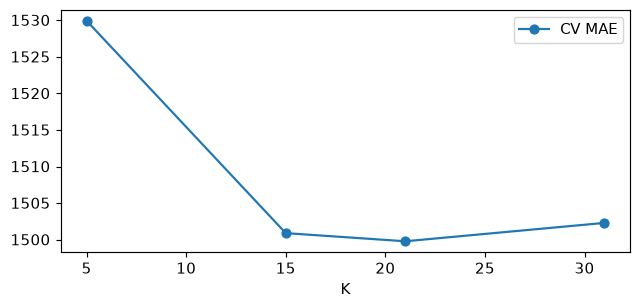

In [12]:
knn = make_pipeline(StandardScaler(), KNeighborsRegressor(weights='distance', n_jobs=2))
search = GridSearchCV(knn, {'kneighborsregressor__n_neighbors': [5, 15, 21, 31]}, scoring='neg_mean_absolute_error', cv=cv, error_score='raise')
search.fit(X_train, y_train)
tuned['KNN'] = search.best_estimator_
tuning_rows.append(['KNN', search.best_params_, -search.best_score_, mean_absolute_error(y_val, search.predict(X_val))])
k_scores = pd.DataFrame({'K': [5, 15, 21, 31], 'CV MAE': -search.cv_results_['mean_test_score']})
display(k_scores)
k_scores.plot(x='K', y='CV MAE', marker='o', figsize=(7, 3))
plt.show()


Đồ thị K để nhìn xu hướng. Chọn K bằng MAE nhỏ nhất trên 3 lượt, không đoán bằng mắt.
RUN_TREE_SEARCH = True: tìm thêm độ sâu và số mẫu trong lá của cây/rừng; chạy lâu hơn.
Bảng mô hình ban đầu và bảng sau tối ưu được giữ riêng để đối chiếu.


In [13]:
RUN_TREE_SEARCH = False  # Đổi True để tìm thêm tham số cây/rừng; chạy lâu hơn.
if RUN_TREE_SEARCH:
    for name in ['Decision Tree', 'Random Forest']:
        grid = {'max_depth': [8, 14], 'min_samples_leaf': [5, 20, 50]}
        search = GridSearchCV(models[name], grid, scoring='neg_mean_absolute_error', cv=cv, error_score='raise')
        search.fit(X_train, y_train)
        tuned[name] = search.best_estimator_
        tuning_rows.append([name, search.best_params_, -search.best_score_, mean_absolute_error(y_val, search.predict(X_val))])
else:
    print('Tree/forest tuning was skipped; their starting models were evaluated in section 4.')
tuning_results = pd.DataFrame(tuning_rows, columns=['Model', 'Chosen settings', 'CV MAE', 'Validation MAE'])
display(tuning_results)
print('Starting Linear validation MAE:', results.loc['Linear', 'MAE'])


Tree/forest tuning was skipped; their starting models were evaluated in section 4.
Starting Linear validation MAE: 318.9880780701971


,Model,Chosen settings,CV MAE,Validation MAE
0,Ridge,{'ridge__alpha': 0.001},370.11,318.99
1,Lasso,{'lasso__alpha': 1},368.17,322.43
2,KNN,{'kneighborsregressor__n_neighbors': 21},"1,499.79","1,715.34"


## 7. Kiểm tra đặc trưng có ích không
Bỏ thời tiết; rồi bỏ toàn bộ điện hiện tại/quá khứ. Chạy lại Linear và so MAE.


In [14]:
groups = {'All 48 inputs': list(X.columns),
          'Without weather': [c for c in X if c not in weather],
          'Without current/history electricity': weather + [c for c in X if c.startswith(('clock_', 'weekday_', 'year_')) or c == 'is_weekend']}
ablation = []
for name, columns in groups.items():
    model = make_pipeline(StandardScaler(), LinearRegression())
    model.fit(X_train[columns], y_train)
    ablation.append([name, len(columns), mean_absolute_error(y_val, model.predict(X_val[columns]))])
display(pd.DataFrame(ablation, columns=['Inputs', 'Count', 'Validation MAE']))


,Inputs,Count,Validation MAE
0,All 48 inputs,48,318.99
1,Without weather,43,318.88
2,Without current/history electricity,12,"4,881.07"


## 8. Ý tưởng 1 — Cảnh báo điện cao
Logistic dự đoán khả năng điện cao ở khu vực 1.
Ngưỡng cao lấy từ train: nhóm 10% giá trị cao nhất; chưa phải ngưỡng quá tải.
Precision: cảnh báo đúng bao nhiêu. Recall: bắt được bao nhiêu trường hợp cao.
Điểm dự đoán chưa được kiểm chứng như xác suất thực tế.


In [15]:
high_limit = y_train.zone_1.quantile(0.90)
high_train = (y_train.zone_1 >= high_limit).astype(int)
high_val = (y_val.zone_1 >= high_limit).astype(int)
alert_model = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1500))
alert_model.fit(X_train, high_train)
probability = alert_model.predict_proba(X_val)[:, 1]
alerts = probability >= 0.5
print('High-demand threshold (source units):', high_limit)
print('Precision:', precision_score(high_val, alerts, zero_division=0), '| Recall:', recall_score(high_val, alerts, zero_division=0))


High-demand threshold (source units): 43101.95745
Precision: 0.8530042918454935 | Recall: 0.9987437185929648


## 9. Chọn ngưỡng cảnh báo
Ví dụ: điểm phạt = 20 × số lần bỏ sót + số lần báo nhầm.
Chọn ngưỡng ở nửa đầu validation; chấm ở nửa sau, bỏ 3 dòng sát ranh giới.
Mỗi lần đếm là một dòng dữ liệu. Đây là điểm giả định, chưa phải tiền tiết kiệm.


In [16]:
boundary = origin[validation].iloc[len(X_val) // 2]
calibration = (target_time[validation] < boundary).to_numpy()
assessment = (origin[validation] >= boundary).to_numpy()
print('Threshold choice rows:', calibration.sum(), '| Assessment rows:', assessment.sum())
policy_results = []
for miss_penalty in [1, 20, 200]:
    choices = []
    for threshold in np.arange(0, 1.01, 0.05):
        alert = probability[calibration] >= threshold
        truth = high_val.to_numpy()[calibration]
        misses = ((truth == 1) & ~alert).sum()
        false_alarms = ((truth == 0) & alert).sum()
        choices.append([miss_penalty * misses + false_alarms, threshold])
    chosen = min(choices)[1]
    for name, threshold in [('Fixed 0.5', 0.5), ('Chosen on early validation', chosen)]:
        alert = probability[assessment] >= threshold
        truth = high_val.to_numpy()[assessment]
        misses = ((truth == 1) & ~alert).sum()
        false_alarms = ((truth == 0) & alert).sum()
        policy_results.append([miss_penalty, name, threshold, misses, false_alarms, miss_penalty * misses + false_alarms])
policy_results = pd.DataFrame(policy_results, columns=['Miss penalty', 'Method', 'Threshold', 'Misses', 'False alarms', 'Penalty points'])
display(policy_results)


Threshold choice rows: 3926 | Assessment rows: 3930


,Miss penalty,Method,Threshold,Misses,False alarms,Penalty points
0,1,Fixed 0.5,0.50,1,62,63
1,1,Chosen on early validation,0.95,15,7,22
2,20,Fixed 0.5,0.50,1,62,82
3,20,Chosen on early validation,0.60,1,49,69
4,200,Fixed 0.5,0.50,1,62,262
5,200,Chosen on early validation,0.60,1,49,249


## 10. Ý tưởng 2 — Có đầu vào sai thì làm gì?
Cố tình nhân số điện khu vực 1 lên 10 lần để thử.
Số thiếu hoặc vượt khoảng train mở rộng 25% → dùng số hợp lệ trước 10 phút.
Số dự phòng cũng sai → không dự đoán. Đây là thử lỗi giả lập, chưa phải bộ phát hiện lỗi thực tế.


In [17]:
monitored = weather + zones + [f'{z}_lag_1' for z in zones]
minimum, maximum = X_train[monitored].min(), X_train[monitored].max()
span = maximum - minimum
lower, upper = minimum - 0.25 * span, maximum + 0.25 * span
lower.loc[[c for c in monitored if c != 'temperature']] = lower.drop('temperature').clip(lower=0)
upper['humidity'] = min(100, upper['humidity'])
packet = X_val.iloc[[len(X_val) // 2]].copy()
packet['zone_1'] *= 10
finite = np.isfinite(packet.to_numpy()).all()
in_range = packet[monitored].ge(lower).all().all() and packet[monitored].le(upper).all().all()
if finite and in_range:
    guarded = models['Linear'].predict(packet)[0]
    method = 'Linear'
else:
    guarded = []
    for zone in zones:
        reading = packet[f'{zone}_lag_1'].iloc[0]
        safe = np.isfinite(reading) and lower[f'{zone}_lag_1'] <= reading <= upper[f'{zone}_lag_1']
        guarded.append(reading if safe else np.nan)
    method = 'Valid reading from 10 minutes earlier, or unavailable'
display(pd.DataFrame({'Received now': packet[zones].iloc[0], 'Actual in 30 min': y_val.loc[packet.index].iloc[0], 'Guarded forecast': guarded}))
print('Input accepted:', finite and in_range, '| Method:', method)


Input accepted: False | Method: Valid reading from 10 minutes earlier, or unavailable


,Received now,Actual in 30 min,Guarded forecast
zone_1,"262,035.89","26,172.08","26,493.48"
zone_2,"15,542.74","15,124.48","15,561.41"
zone_3,"12,278.66","12,091.91","12,372.04"


## 11. So sánh các mô hình trên train và test
Chỉ mở test sau khi đã chốt mô hình và tham số. Không học hay tìm tham số bằng test.
Giữ cả mô hình ban đầu và mô hình đã tối ưu để đối chiếu.

MAE được dùng chính vì dễ đọc theo đơn vị điện gốc. Tìm Alpha và K cũng dùng MAE để nhất quán.

- MAE: lệch trung bình bao nhiêu; càng nhỏ càng tốt.
- RMSE: phạt lỗi lớn nặng hơn; càng nhỏ càng tốt.
- MAPE (%): trung bình lệch bao nhiêu phần trăm so với số thật; càng nhỏ càng tốt.
- R²: gần 1 thường tốt hơn; có thể âm nếu dự đoán kém.

Dữ liệu điện thực tế đều lớn hơn 0 nên có thể đọc thêm MAPE.
MAE, RMSE và MAPE tính chung ba khu vực; R² lấy trung bình điểm của ba khu vực.
Điểm train tốt nhưng test kém là dấu hiệu mô hình có thể học quá sát dữ liệu cũ.
KNN có thể đạt lỗi train bằng 0 vì gặp lại đúng mẫu đã học.

Đánh giá cuốn chiếu: ở mỗi thời điểm, dùng số đo đã có đến lúc đó để đoán sau 30 phút.
Lấy thêm 7 ngày lịch sử trước test để tạo đủ đầu vào; không lấy số đo tương lai làm đầu vào.


Train: 35680 | Test: 7860


,Train MAE,Train RMSE,Train MAPE (%),Train R2,Test MAE,Test RMSE,Test MAPE (%),Test R2
Model,,,,,,,,
Linear,332.0174,514.3842,1.4339,0.9935,357.3126,538.8285,1.8212,0.9867
Ridge,355.6949,540.5844,1.5408,0.9928,423.3133,607.7440,2.1606,0.9835
Lasso,356.1464,542.1553,1.5418,0.9927,392.7213,573.9470,2.0414,0.9849
KNN,0.0002,0.0005,0.0000,1.0000,"3,453.3077","3,920.7973",20.7752,0.1083
Decision Tree,529.9683,765.7707,2.2808,0.9850,"2,620.9558","3,542.8817",14.4722,0.4677
Random Forest,256.2981,384.8773,1.1215,0.9962,"2,336.8375","3,139.7178",12.7476,0.5947
Ridge (tuned),332.0174,514.3842,1.4339,0.9935,357.3134,538.8292,1.8212,0.9867
Lasso (tuned),336.5944,519.4270,1.4555,0.9933,363.3611,543.2330,1.8664,0.9865
KNN (tuned),0.0003,0.0007,0.0000,1.0000,"3,500.9390","3,950.4804",21.1297,0.0837


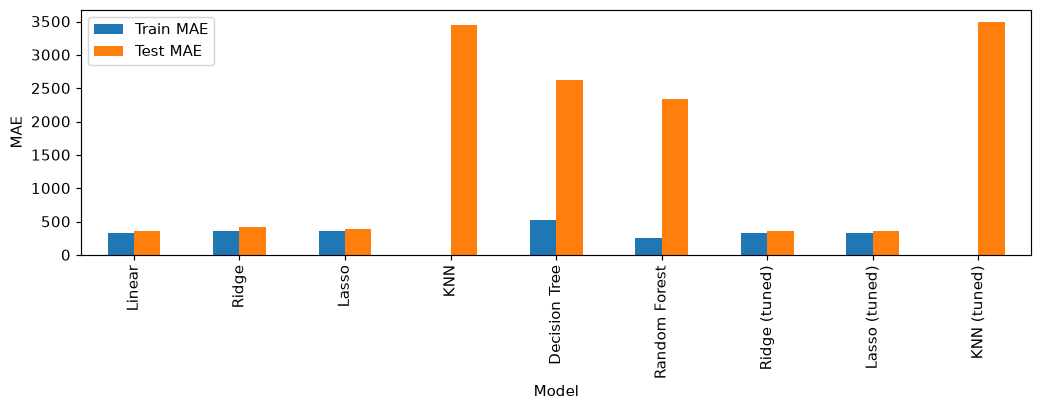

In [18]:
test.columns = df.columns
test['time'] = pd.to_datetime(test['time'], format='%m/%d/%Y %H:%M')
test_history = pd.concat([df.tail(1008), test])  # Bổ sung 7 ngày lịch sử đã có.
X_test, y_test, test_origin, test_target_time = make_features(test_history)
assert X_test.columns.equals(X_train.columns)
assert target_time[validation].max() < test_origin.min()
print('Train:', len(X_train), '| Test:', len(X_test))

final_models = models.copy()
for name, model in tuned.items():
    final_models[name + ' (tuned)'] = model

metric_rows = []
for name, model in final_models.items():
    row = [name]
    for inputs, truth in [(X_train, y_train), (X_test, y_test)]:
        predicted = model.predict(inputs)
        mae = mean_absolute_error(truth, predicted)
        rmse = np.sqrt(mean_squared_error(truth, predicted))
        mape = mean_absolute_percentage_error(truth, predicted) * 100
        r2 = r2_score(truth, predicted)
        row.extend([mae, rmse, mape, r2])
    metric_rows.append(row)

train_test_results = pd.DataFrame(metric_rows, columns=[
    'Model', 'Train MAE', 'Train RMSE', 'Train MAPE (%)', 'Train R2',
    'Test MAE', 'Test RMSE', 'Test MAPE (%)', 'Test R2'
]).set_index('Model')
with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(train_test_results)
train_test_results[['Train MAE', 'Test MAE']].plot.bar(figsize=(10, 4), ylabel='MAE')
plt.tight_layout()
plt.show()


## 12. Lưu kết quả
Lưu 4 bảng CSV. File nằm trong máy Colab; tải xuống nếu muốn giữ.


In [19]:
results.to_csv('validation_model_comparison.csv')
tuning_results.to_csv('tuning_comparison.csv', index=False)
policy_results.to_csv('alert_penalties.csv', index=False)
train_test_results.to_csv('train_test_model_comparison.csv')
print('Đã lưu 4 bảng CSV trong máy Colab.')


Đã lưu 4 bảng CSV trong máy Colab.


## 13. Còn phải làm
- Chốt cách chia dữ liệu chung.
- Đối chiếu nghiên cứu; hoàn thiện báo cáo và slide.
- Kiểm chứng hai ý tưởng ứng dụng. Chương 11–15 chưa làm.

30 phút là lựa chọn của nhóm; yêu cầu đã đọc chưa ấn định 10 hay 30 phút.

Nguồn: [UCI](https://archive.ics.uci.edu/dataset/849/power+consumption+of+tetouan+city)
· [Yêu cầu môn học](https://docs.google.com/spreadsheets/d/17AhxqqU-uAUvH9RTIqbgO1w13_obfjTln45ukoH7SmM/edit)
· [Nghiên cứu Alsalem 2025](https://www.nature.com/articles/s41598-025-91123-8)
· [GitHub nhóm](https://github.com/huy1907ddddddd/DS66B_group_14).
Chỉ so điểm nghiên cứu khác khi cùng dữ liệu, cách chia và thời gian dự đoán.

Test chỉ dùng ở phần 11 sau khi đã chốt mô hình và tham số. Không dùng điểm test để sửa mô hình.
Test cũ đã từng được xem; cần ghi rõ khi chốt cách đánh giá cuối.
